In [1]:
import os
import json 
import numpy as np
from Util.util import load_keypoints_and_labels
from Util.gait_util import GaitRecording
import matplotlib.pyplot as plt
%matplotlib ipympl

In [2]:
# load preprocessed keypoints
recording_name = 'walk1'
filename_stereo = os.path.join('data', recording_name, recording_name+'_stereo.npz')
filename_qualisys = os.path.join('data', recording_name, recording_name+'_qualisys.npz')

stereo_keypoints, stereo_labels = load_keypoints_and_labels(filename=filename_stereo)
qualisys_keypoints, qualisys_labels = load_keypoints_and_labels(filename=filename_qualisys)

loaded data from: data\walk1\walk1_stereo.npz with keys: ['labels', 'keypoints']
loaded data from: data\walk1\walk1_qualisys.npz with keys: ['labels', 'keypoints']


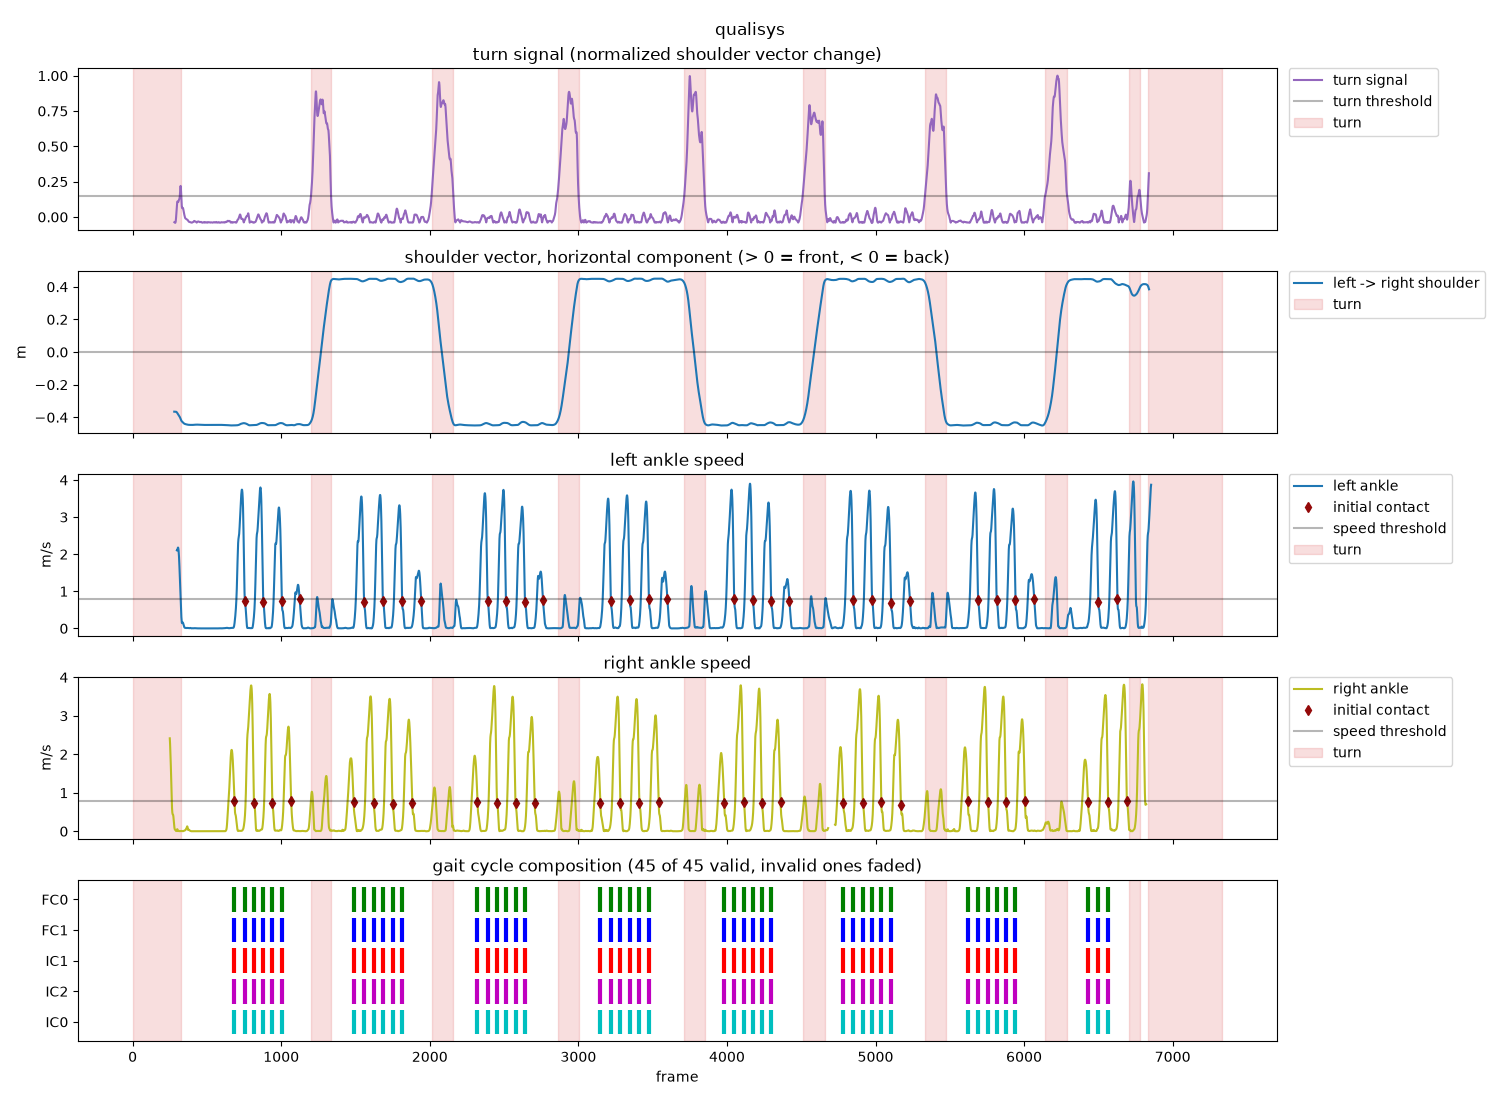

In [3]:
q_walk = GaitRecording('qualisys',qualisys_keypoints, qualisys_labels,100)
q_walk.analyze()
fig = q_walk.plot()

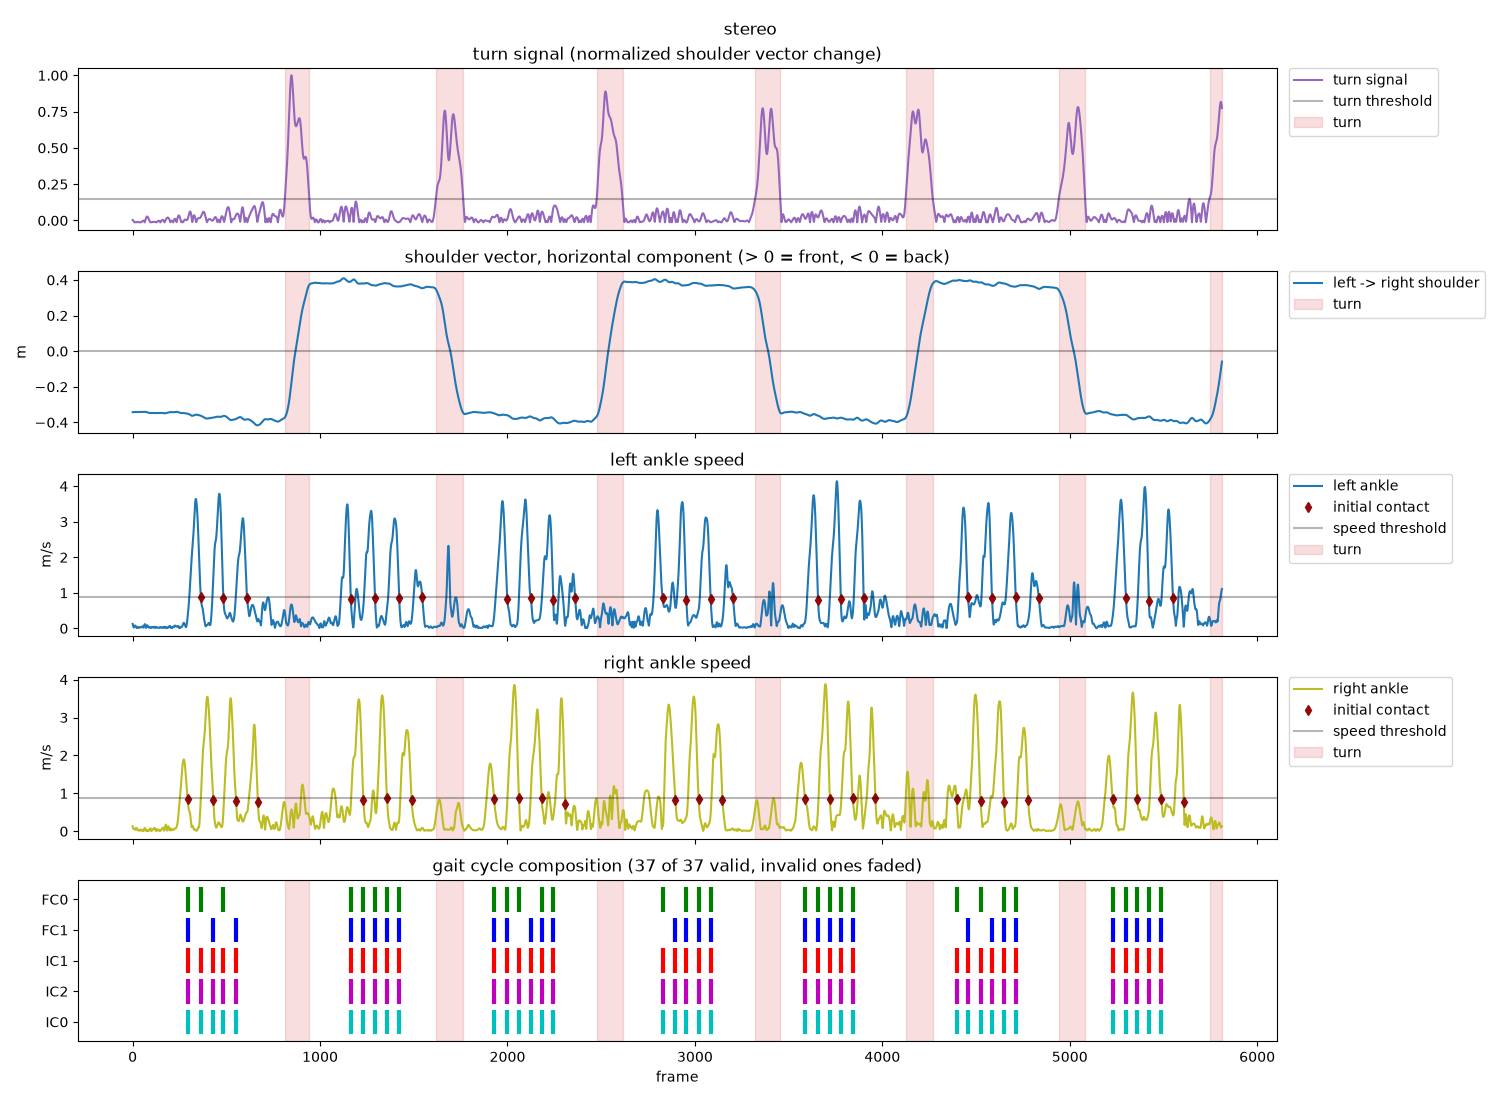

In [4]:
s_cut_1 = 650
s_walk = GaitRecording('stereo', stereo_keypoints[s_cut_1:,:,:], stereo_labels, 100)
s_walk.analyze()
fig = s_walk.plot()

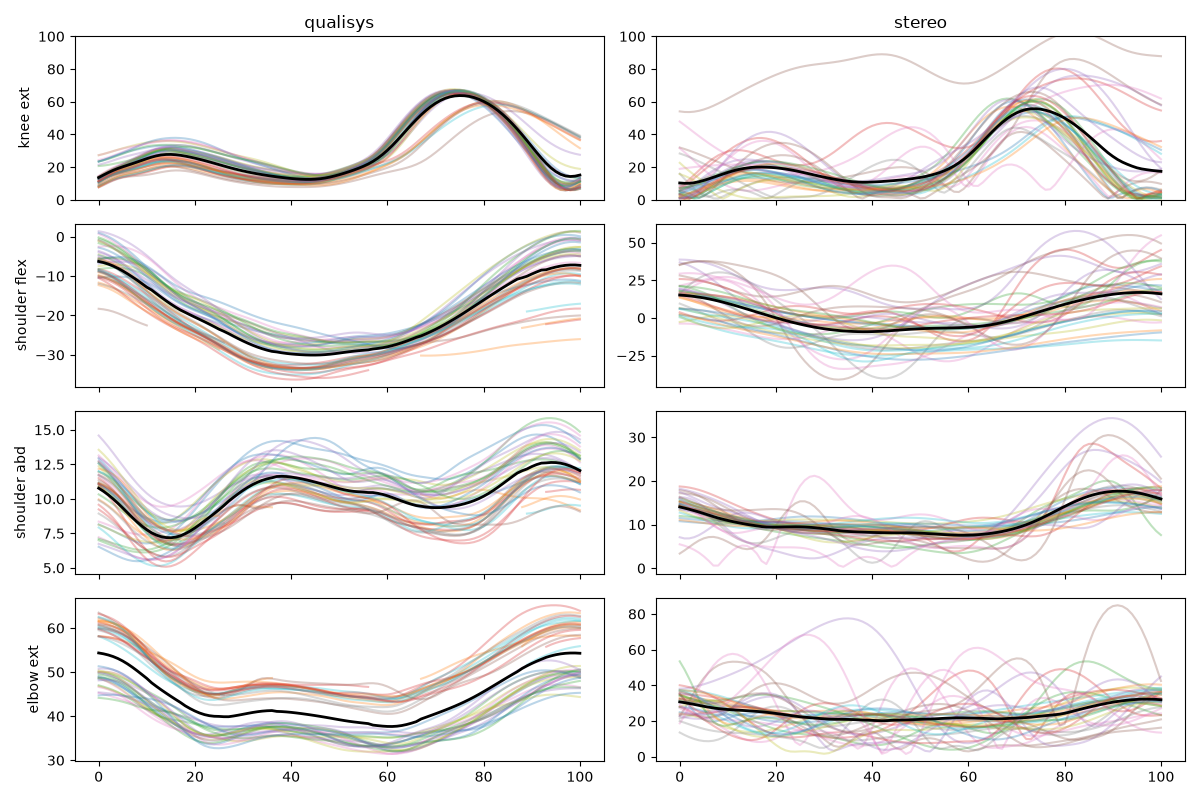

In [33]:

plt.close('all')
fig, axs = plt.subplots(4,2,figsize=(12,8), sharex=True)
flat = axs.flat
flat[0].set_title('qualisys')
flat[0].set_ylim([0,100])
flat[1].set_title('stereo')
flat[1].set_ylim([0,100])
flat[0].set_ylabel('knee ext')
flat[2].set_ylabel('shoulder flex')
flat[4].set_ylabel('shoulder abd')
flat[6].set_ylabel('elbow ext')
gait_percent = np.linspace(0, 100, 101)
angle_names = ['knee_ext_angles', 'shoulder_flex_angles', 'shoulder_abd_angles', 'elbow_ext_angles']

for column_index, walk in enumerate([q_walk, s_walk]):
    valid_cycles = [gc for gc in walk.gait_cycles if gc.valid]
    for row_index, angle_name in enumerate(angle_names):
        ax = axs[row_index, column_index]
        normalized_cycles = []
        for gc in valid_cycles:
            angles = np.asarray(getattr(gc, angle_name))
            cycle_percent = np.linspace(0, 100, len(angles))
            normalized_angles = np.interp(gait_percent, cycle_percent, angles)
            ax.plot(gait_percent, normalized_angles, alpha=0.3)
            normalized_cycles.append(normalized_angles)
        ax.plot(gait_percent, np.nanmean(normalized_cycles, axis=0), color='k', linewidth=2)
plt.tight_layout()

Text(0, 0.5, 'thigh length [m]')

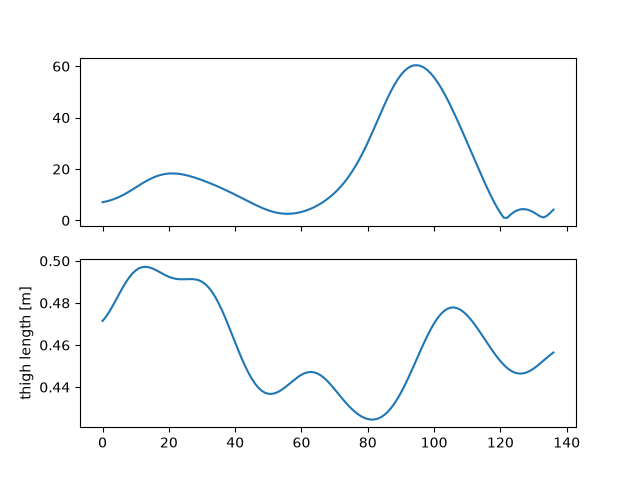

In [34]:
gc = [g for g in s_walk.gait_cycles if g.valid][0]
hip  = s_walk.keypoints[gc.IC0.frame:gc.IC2.frame, stereo_labels.index(f'{gc.ipsi}_hip')]
knee = s_walk.keypoints[gc.IC0.frame:gc.IC2.frame, stereo_labels.index(f'{gc.ipsi}_knee')]
fig, (ax_angle, ax_length) = plt.subplots(2, 1, sharex=True)
ax_angle.plot(gc.knee_ext_angles)
ax_length.plot(np.linalg.norm(knee - hip, axis=1)); ax_length.set_ylabel('thigh length [m]')
